In [23]:
import glob, re
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature


In [24]:
# --- paramètres ---
data_dir = "/home/nora/projects/NeurOST/input_data/cmems_sla/swon"
lon_min, lon_max = -65, -55
lat_min, lat_max = 34, 42
var = "sla_filtered"          # ou "sla_unfiltered" selon ce que tu veux

In [25]:
# --- 1. lister les fichiers (récursif au cas où il y a des sous-dossiers année/mois) ---
files = sorted(glob.glob(f"{data_dir}/**/*.nc", recursive=True))
print(f"{len(files)} fichiers trouvés")

428 fichiers trouvés


In [26]:
# --- 2. garder ceux qui ont des points dans la boîte ---
def in_box(ds):
    lon = ((ds.longitude + 180) % 360) - 180
    return ((lon > lon_min) & (lon < lon_max) &
            (ds.latitude > lat_min) & (ds.latitude < lat_max)).values

selected = []
for f in files:
    with xr.open_dataset(f) as ds:
        if in_box(ds).any():
            selected.append(f)
print(f"{len(selected)} fichiers avec des données dans la boîte Gulf Stream")

228 fichiers avec des données dans la boîte Gulf Stream


In [27]:
# --- 3. prendre un jour en exemple et ne garder que les points dans la boîte ---
f = selected[0]
date = re.search(r"_(\d{8})_", f).group(1)
ds = xr.open_dataset(f)
ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180)
ds_box = ds.isel(time=in_box(ds))

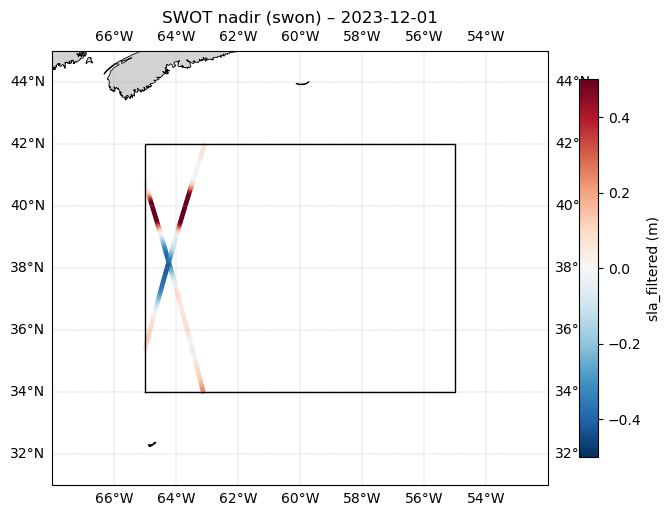

In [28]:
# --- 4. carte ---
fig, ax = plt.subplots(figsize=(8, 7), subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent([lon_min - 3, lon_max + 3, lat_min - 3, lat_max + 3])
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.gridlines(draw_labels=True, linewidth=0.3, linestyle="--")

sc = ax.scatter(ds_box.longitude, ds_box.latitude, c=ds_box[var],
                s=6, cmap="RdBu_r", vmin=-0.5, vmax=0.5,
                transform=ccrs.PlateCarree())
plt.colorbar(sc, ax=ax, shrink=0.7, label=f"{var} (m)")

ax.plot([lon_min, lon_max, lon_max, lon_min, lon_min],
        [lat_min, lat_min, lat_max, lat_max, lat_min],
        "k-", lw=1, transform=ccrs.PlateCarree())
ax.set_title(f"SWOT nadir (swon) – {date[:4]}-{date[4:6]}-{date[6:]}")
plt.show()

In [29]:
# --- séparer les passes par les sauts de temps ---
t = ds_box.time.values
gap = np.diff(t) > np.timedelta64(5, "m")      # saut > 5 min = nouvelle passe
pass_id = np.concatenate([[0], np.cumsum(gap)])
ds_box = ds_box.assign_coords(pass_id=("time", pass_id))

print(f"{pass_id.max() + 1} passes dans la boîte")
for i in range(pass_id.max() + 1):
    tt = t[pass_id == i]
    print(i, tt[0], "→", tt[-1], f"({len(tt)} points)")

# --- n'en garder qu'une ---
ds_pass = ds_box.isel(time=(pass_id == 1))     # 0 = la première, 1 = la deuxième...

2 passes dans la boîte
0 2023-12-01T00:56:16.042012672 → 2023-12-01T00:58:15.058012672 (109 points)
1 2023-12-01T14:10:18.474867200 → 2023-12-01T14:12:15.286866944 (107 points)


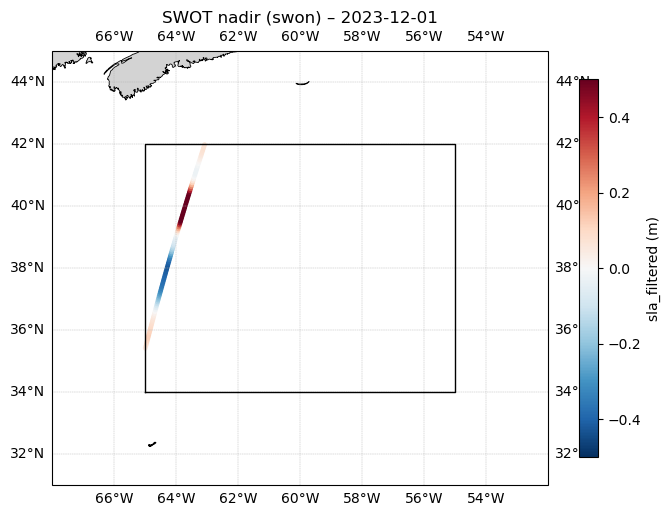

In [30]:
# --- 4. carte ---
fig, ax = plt.subplots(figsize=(8, 7), subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent([lon_min - 3, lon_max + 3, lat_min - 3, lat_max + 3])
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.gridlines(draw_labels=True, linewidth=0.3, linestyle="--")

sc = ax.scatter(ds_pass.longitude, ds_pass.latitude, c=ds_pass[var],
                s=6, cmap="RdBu_r", vmin=-0.5, vmax=0.5,
                transform=ccrs.PlateCarree())
plt.colorbar(sc, ax=ax, shrink=0.7, label=f"{var} (m)")

ax.plot([lon_min, lon_max, lon_max, lon_min, lon_min],
        [lat_min, lat_min, lat_max, lat_max, lat_min],
        "k-", lw=1, transform=ccrs.PlateCarree())
ax.set_title(f"SWOT nadir (swon) – {date[:4]}-{date[4:6]}-{date[6:]}")
plt.show()

In [31]:
def n_passes(f, gap_min=5):
    with xr.open_dataset(f) as ds:
        m = in_box(ds)
        if not m.any():
            return 0
        t = ds.time.values[m]
        return int(np.sum(np.diff(t) > np.timedelta64(gap_min, "m"))) + 1

counts = {re.search(r"_(\d{8})_", f).group(1): n_passes(f) for f in selected}
n_min= min(counts.values())
n_max = max(counts.values())
jours_max = [d for d, n in counts.items() if n == n_max]
jours_min = [d for d, n in counts.items() if n == n_min]

print(f"Nombre maximal de passes dans la boîte : {n_max}")
print(f"Atteint le(s) jour(s) : {jours_max}")

print(f"Nombre minimal de passes dans la boîte : {n_min}")

# distribution
from collections import Counter
print(Counter(counts.values()))

Nombre maximal de passes dans la boîte : 2
Atteint le(s) jour(s) : ['20231201', '20231208', '20231209', '20231210', '20231211', '20231218', '20231219', '20231220', '20231221', '20231229', '20231230', '20231231', '20240101', '20240108', '20240110', '20240111', '20240119', '20240120', '20240121', '20240122', '20240129', '20240130', '20240131', '20240201', '20240209', '20240210', '20240211', '20240212', '20240219', '20240220', '20240221', '20240222', '20240229', '20240301', '20240302', '20240303', '20240304', '20240310', '20240311', '20240312', '20240313', '20240314', '20240321', '20240322', '20240323', '20240324', '20240325', '20240331', '20240401', '20240402', '20240403', '20240404', '20240411', '20240412', '20240413', '20240414', '20240415', '20240421', '20240422', '20240423', '20240424', '20240425', '20240502', '20240503', '20240504', '20240505', '20240506', '20240512', '20240513', '20240514', '20240515', '20240523', '20240524', '20240525', '20240526', '20240602', '20240603', '2024060

In [32]:
from collections import Counter
import pandas as pd

# tous les fichiers, pas seulement 'selected'
counts_all = {re.search(r"_(\d{8})_", f).group(1): n_passes(f) for f in files}

# tous les jours de la période, même ceux sans fichier
jours = pd.date_range(min(counts_all), max(counts_all), freq="D").strftime("%Y%m%d")
counts_full = {d: counts_all.get(d, 0) for d in jours}

manquants = [d for d in jours if d not in counts_all]
print(f"{len(jours)} jours au total, {len(manquants)} sans fichier")
print(Counter(counts_full.values()))

428 jours au total, 0 sans fichier
Counter({0: 200, 2: 177, 1: 51})


In [33]:
print(f'nombre de jours sans passe dans la boîte = {len(files)-len(selected)}')

nombre de jours sans passe dans la boîte = 200


In [34]:
rows = []
for f in selected:
    date = re.search(r"_(\d{8})_", f).group(1)
    with xr.open_dataset(f) as ds:
        lon = ((ds.longitude + 180) % 360) - 180
        m = in_box(ds)
        t, la, lo = ds.time.values[m], ds.latitude.values[m], lon.values[m]
    pid = np.concatenate([[0], np.cumsum(np.diff(t) > np.timedelta64(5, "m"))])
    for i in np.unique(pid):
        k = pid == i
        rows.append(dict(date=pd.to_datetime(date), t0=t[k][0], n=k.sum(),
                         sens="montante" if la[k][-1] > la[k][0] else "descendante",
                         lon_moy=lo[k].mean()))

passes = pd.DataFrame(rows)
print(passes.head(30))
print(passes.groupby("sens").size())

         date                            t0    n         sens    lon_moy
0  2023-12-01 2023-12-01 00:56:16.042012672  109  descendante -64.024800
1  2023-12-01 2023-12-01 14:10:18.474867200  107     montante -64.072108
2  2023-12-07 2023-12-07 23:16:37.148681728   97  descendante -55.860583
3  2023-12-08 2023-12-08 12:30:36.804317184  101     montante -55.891703
4  2023-12-08 2023-12-08 23:17:07.720616960  129  descendante -58.055290
5  2023-12-09 2023-12-09 12:31:08.494216704  129     montante -58.091348
6  2023-12-09 2023-12-09 23:17:39.391011328  129  descendante -60.507788
7  2023-12-10 2023-12-10 12:31:39.029736960  128     montante -60.564986
8  2023-12-10 2023-12-10 23:18:09.902370304  129  descendante -62.978821
9  2023-12-11 2023-12-11 12:32:09.679879680  129     montante -63.032537
10 2023-12-11 2023-12-11 23:20:18.570860032   40  descendante -64.678603
11 2023-12-12 2023-12-12 12:34:23.825613312   35     montante -64.659247
12 2023-12-17 2023-12-17 21:38:53.644774912   27  d

In [35]:
import os, shutil

out_dir = "/home/nora/projects/NeurOST/input_data/cmems_sla/swon_gulfstream"
os.makedirs(out_dir, exist_ok=True)

for f in selected:
    shutil.copy2(f, out_dir)          # copie en gardant les dates du fichier

print(f"{len(selected)} fichiers copiés dans {out_dir}")

228 fichiers copiés dans /home/nora/projects/NeurOST/input_data/cmems_sla/swon_gulfstream


In [36]:
rows = []
for f in selected:
    date = re.search(r"_(\d{8})_", f).group(1)
    with xr.open_dataset(f) as ds:
        m = in_box(ds)
        idx = np.where(m)[0]                       # indices des points dans la boîte
        t = ds.time.values[idx]
        la = ds.latitude.values[idx]
    pid = np.concatenate([[0], np.cumsum(np.diff(t) > np.timedelta64(5, "m"))])
    for i in np.unique(pid):
        k = pid == i
        rows.append(dict(file=f, date=date, t0=t[k][0], n=k.sum(),
                         lat_span=la[k].max() - la[k].min(),
                         sens="montante" if la[k][-1] > la[k][0] else "descendante",
                         idx=idx[k]))
passes = pd.DataFrame(rows)
print(f"{len(passes)} passes au total")
print(passes.n.describe())

405 passes au total
count    405.000000
mean     102.760494
std       36.775132
min       23.000000
25%       97.000000
50%      124.000000
75%      128.000000
max      129.000000
Name: n, dtype: float64


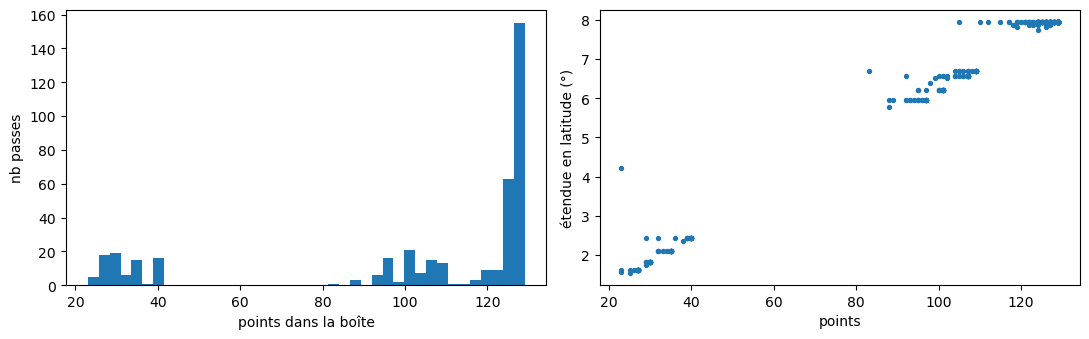

In [37]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].hist(passes.n, bins=40); axs[0].set_xlabel("points dans la boîte"); axs[0].set_ylabel("nb passes")
axs[1].scatter(passes.n, passes.lat_span, s=8); axs[1].set_xlabel("points"); axs[1].set_ylabel("étendue en latitude (°)")
plt.tight_layout(); plt.show()

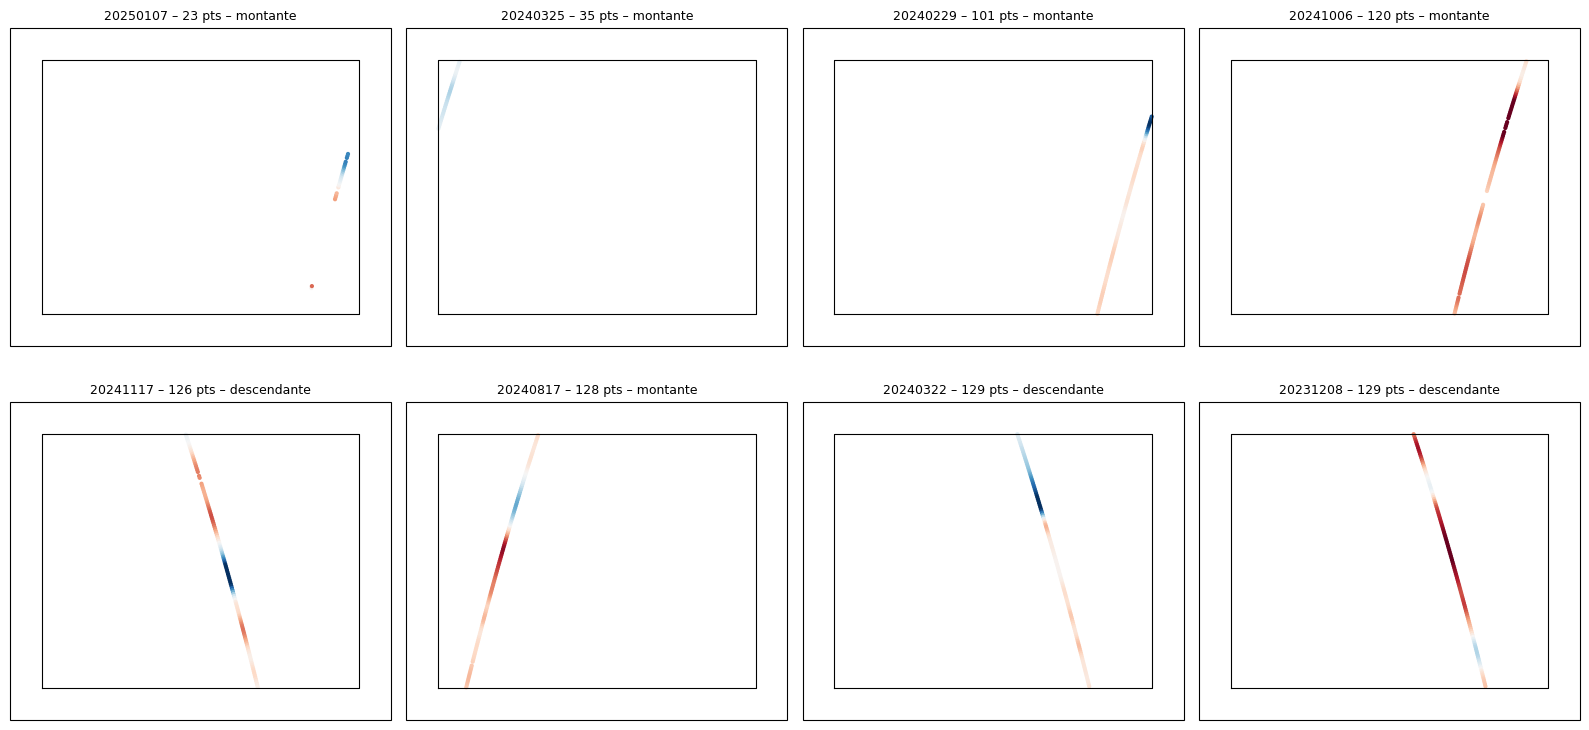

In [38]:
ex = passes.sort_values("n").iloc[np.linspace(0, len(passes) - 1, 8).astype(int)]

fig, axs = plt.subplots(2, 4, figsize=(16, 8), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, (_, p) in zip(axs.flat, ex.iterrows()):
    with xr.open_dataset(p.file) as ds:
        d = ds.isel(time=p.idx)
        lon = ((d.longitude + 180) % 360) - 180
        ax.scatter(lon, d.latitude, c=d[var], s=4, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
    ax.set_extent([lon_min - 1, lon_max + 1, lat_min - 1, lat_max + 1])
    ax.coastlines(lw=0.5)
    ax.plot([lon_min, lon_max, lon_max, lon_min, lon_min],
            [lat_min, lat_min, lat_max, lat_max, lat_min], "k-", lw=0.8)
    ax.set_title(f"{p.date} – {p.n} pts – {p.sens}", fontsize=9)
plt.tight_layout(); plt.show()

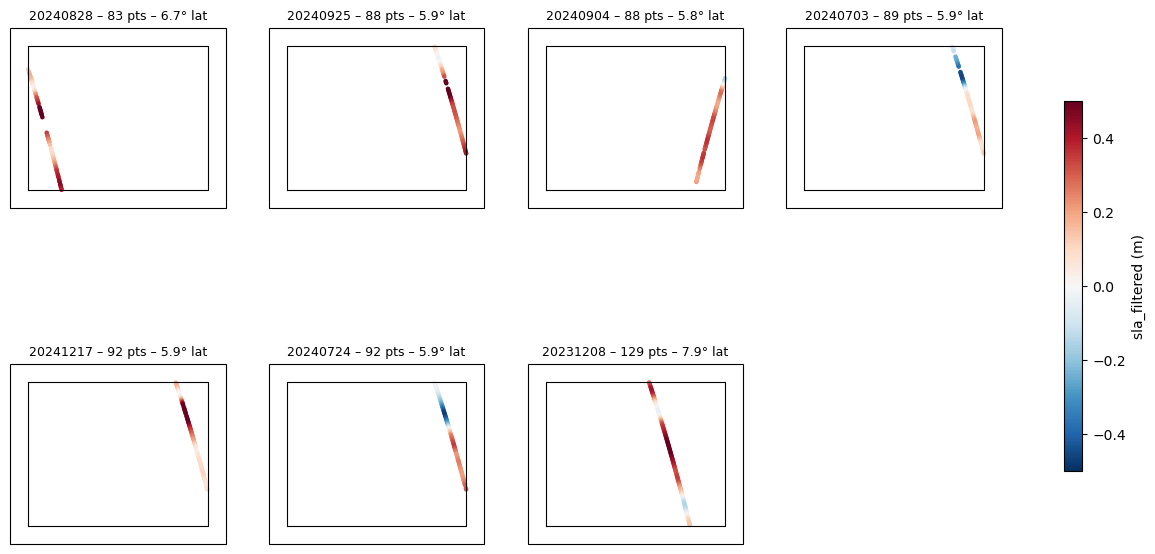

Passes avec ≥ 50 points : 325 / 405


In [41]:
# passes les plus proches de 50 points
autour = passes.iloc[(passes.n - 70).abs().argsort()[:6]]
# + une passe "complète" pour comparer
ref = passes.loc[[passes.n.idxmax()]]
ex = pd.concat([autour, ref])

fig, axs = plt.subplots(2, 4, figsize=(16, 8), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, (_, p) in zip(axs.flat, ex.iterrows()):
    with xr.open_dataset(p.file) as ds:
        d = ds.isel(time=p.idx)
        lon = ((d.longitude + 180) % 360) - 180
        sc = ax.scatter(lon, d.latitude, c=d[var], s=5, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
    ax.set_extent([lon_min - 1, lon_max + 1, lat_min - 1, lat_max + 1])
    ax.coastlines(lw=0.5)
    ax.plot([lon_min, lon_max, lon_max, lon_min, lon_min],
            [lat_min, lat_min, lat_max, lat_max, lat_min], "k-", lw=0.8)
    ax.set_title(f"{p.date} – {p.n} pts – {p.lat_span:.1f}° lat", fontsize=9)
axs.flat[-1].axis("off")
fig.colorbar(sc, ax=axs, shrink=0.6, label=f"{var} (m)")
plt.show()

print(f"Passes avec ≥ 50 points : {(passes.n >= 50).sum()} / {len(passes)}")

In [42]:
n_min = 50          # à ajuster d'après les figures

good = passes[passes.n >= n_min]
print(f"{len(good)} / {len(passes)} passes gardées")

out_dir = "/home/nora/projects/NeurOST/input_data/cmems_sla/swon_gulfstream_passes"
os.makedirs(out_dir, exist_ok=True)

for _, p in good.iterrows():
    with xr.open_dataset(p.file) as ds:
        d = ds.isel(time=p.idx).load()
    name = f"swon_{pd.Timestamp(p.t0):%Y%m%d_%H%M}_{p.sens}.nc"
    d.to_netcdf(os.path.join(out_dir, name))

325 / 405 passes gardées


/home/nora/miniconda3/envs/neurost_nora/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3699: SerializationWarning: saving variable latitude with floating point data as an integer dtype without any _FillValue to use for NaNs
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/nora/miniconda3/envs/neurost_nora/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3699: SerializationWarning: saving variable longitude with floating point data as an integer dtype without any _FillValue to use for NaNs
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/nora/miniconda3/envs/neurost_nora/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3699: SerializationWarning: saving variable latitude with floating point data as an integer dtype without any _FillValue to use for NaNs
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/nora/miniconda3/envs/neurost_nora/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3699: SerializationWarni